<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/WeeklyModules/Week07/Week_07_Participation_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP607 Week 7 Participation Activity


## Part 1. Clone the MSSP607 GitHub Repository



```text
MSSP607/
└── data/
    └── InternetSales.csv
```

In [1]:
from pathlib import Path
import os
import subprocess

REPO_URL = "https://github.com/kaixing189/MSSP607.git"
REPO_DIR = Path("/content/MSSP607")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
    print("Repository already exists. Latest changes were pulled.")
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    print("Repository cloned successfully.")

os.chdir(REPO_DIR)
print("Current working directory:", os.getcwd())

Repository cloned successfully.
Current working directory: /content/MSSP607


## Part 2. Load the Internet Sales Data



In [2]:
import pandas as pd

DATA_PATH = REPO_DIR / "data" / "InternetSales.csv"

print("Data file exists:", DATA_PATH.exists())

sales = pd.read_csv(
    DATA_PATH,
    encoding="cp1252",
    low_memory=False
)

print("DataFrame shape:", sales.shape)
sales.head()

Data file exists: True
DataFrame shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


The supplied data contain **60,398 rows and 60 columns**.

The two variables needed for this activity are:

- `OrderDate`: the date of the sales order
- `SalesAmount`: the sales amount for the transaction

## Part 3. Convert the Order Date and Create a Year Variable


In [3]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["Year"] = sales["OrderDate"].dt.year

print("OrderDate data type:", sales["OrderDate"].dtype)
print("Years in the data:", sorted(sales["Year"].unique()))

OrderDate data type: datetime64[ns]
Years in the data: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]


## Part 4. Calculate Total Sales by Year



In [4]:
yearly_sales = (
    sales.groupby("Year", as_index=False)["SalesAmount"]
    .sum()
    .sort_values("Year")
)

yearly_sales

,Year,SalesAmount
0,2010,4.342104e+04
1,2011,7.075526e+06
2,2012,5.842485e+06
3,2013,1.635155e+07
4,2014,4.569472e+04


### Yearly sales totals

Using the supplied data, the yearly totals are approximately:

| Year | Total Sales |
|---|---:|
| 2010 | $43,421.04 |
| 2011 | $7,075,525.93 |
| 2012 | $5,842,485.20 |
| 2013 | $16,351,550.34 |
| 2014 | $45,694.72 |

The bar chart in the next section displays these totals.

## Part 5. Create a Bar Chart of Yearly Sales



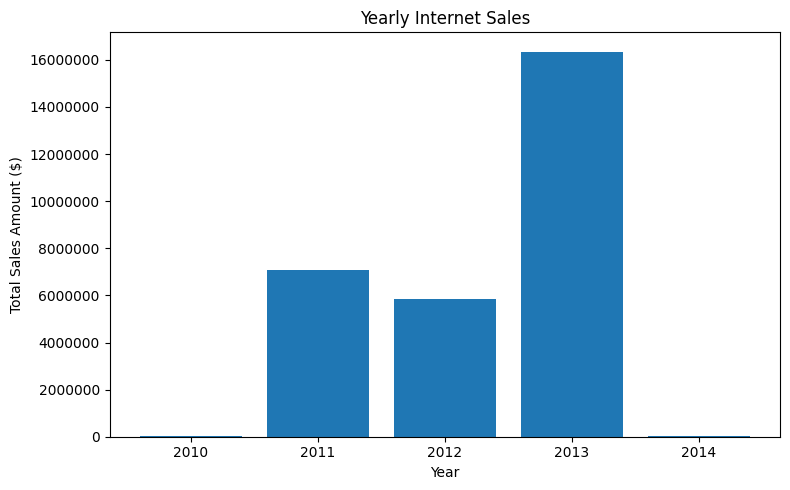

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    yearly_sales["Year"].astype(str),
    yearly_sales["SalesAmount"]
)

ax.set_title("Yearly Internet Sales")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales Amount ($)")
ax.ticklabel_format(style="plain", axis="y")

fig.tight_layout()

## Part 6. Save the Active Figure as a PDF


In [6]:
OUTPUT_DIR = REPO_DIR / "WeeklyModules" / "Week07"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PDF_PATH = OUTPUT_DIR / "Week_07_Yearly_Sales_Bar_Chart.pdf"

plt.savefig(
    PDF_PATH,
    format="pdf",
    bbox_inches="tight"
)

plt.show()

print("PDF saved to:", PDF_PATH)
print("PDF exists:", PDF_PATH.exists())

<Figure size 640x480 with 0 Axes>

PDF saved to: /content/MSSP607/WeeklyModules/Week07/Week_07_Yearly_Sales_Bar_Chart.pdf
PDF exists: True


## Part 7. Final Verification



In [7]:
assert "OrderDate" in sales.columns
assert "SalesAmount" in sales.columns
assert "Year" in sales.columns
assert yearly_sales["Year"].tolist() == [2010, 2011, 2012, 2013, 2014]
assert PDF_PATH.exists()

print("All Week 7 activity checks passed.")
print("Number of yearly totals:", len(yearly_sales))
print("PDF file:", PDF_PATH.name)

All Week 7 activity checks passed.
Number of yearly totals: 5
PDF file: Week_07_Yearly_Sales_Bar_Chart.pdf
